### Part (a)

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import torch
from torch import nn
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import Image, display


In [2]:
def save_figure(fig, folder, name):
    fig.savefig(folder / (name + '.png'), dpi=300)
    fig.savefig(folder / (name + '.svg'), dpi=300)
    display(Image(filename=str(folder / (name + '.png')), width=int(fig.get_figwidth() * 100)))
    plt.close(fig)


In [3]:
folder = Path('.')
train = pd.read_csv(folder / 'train.csv')
val = pd.read_csv(folder / 'val.csv')
test = pd.read_csv(folder / 'test.csv')
x_train = train[['x1', 'x2']].to_numpy()
x_val = val[['x1', 'x2']].to_numpy()
x_test = test[['x1', 'x2']].to_numpy()
y_train = train.y.to_numpy()
y_val = val.y.to_numpy()
plt.rcParams.update({'font.size': 9, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.linewidth': 0.7, 'axes.labelcolor': '#111111', 'text.color': '#111111'})
(low, high) = (y_train.min(), y_train.max())
pd.DataFrame({"split": ["train", "validation", "test"], "rows": [len(train), len(val), len(test)], "columns": [train.shape[1], val.shape[1], test.shape[1]]})


,split,rows,columns
0,train,600,3
1,validation,200,3
2,test,200,2


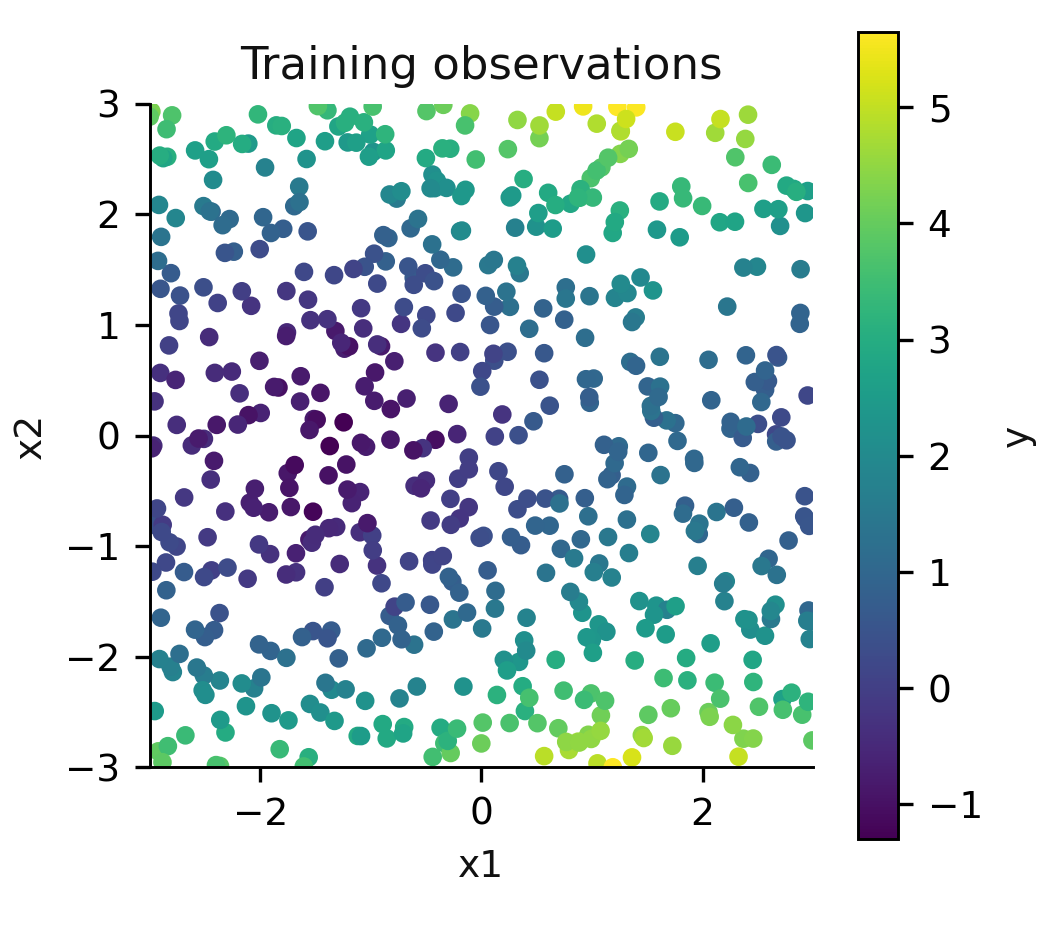

In [4]:
(fig, ax) = plt.subplots(figsize=(3.5, 3.1), layout='constrained')
scatter = ax.scatter(x_train[:, 0], x_train[:, 1], c=y_train, s=12, cmap='viridis', vmin=low, vmax=high)
ax.set(xlabel='x1', ylabel='x2', title='Training observations', xlim=(-3, 3), ylim=(-3, 3), aspect='equal')
fig.colorbar(scatter, ax=ax, label='y')
save_figure(fig, folder, 'training_data')


### Part (b)

In [5]:
def features(x, w, b):
    angles = x @ w + b
    z = np.stack([np.sin(angles), np.cos(angles)], axis=2).reshape(len(x), -1)
    return np.column_stack([z, np.ones(len(x))])

def fit_rks(z, y, ridge):
    penalty = np.eye(z.shape[1])
    penalty[-1, -1] = 0
    return np.linalg.solve(z.T @ z + ridge * penalty, z.T @ y)


In [6]:
rng = np.random.default_rng(42)
w = rng.normal(size=(2, 256))
b = rng.uniform(0, 2 * np.pi, size=256)
z_train = features(x_train, w, b)
z_val = features(x_val, w, b)
rks_rows = []
for ridge in np.logspace(-6, 2, 9):
    coefficients = fit_rks(z_train, y_train, ridge)
    row = {'ridge_lambda': ridge, 'train_mse': np.mean((z_train @ coefficients - y_train) ** 2), 'val_mse': np.mean((z_val @ coefficients - y_val) ** 2)}
    rks_rows.append(row)
rks_results = pd.DataFrame(rks_rows)
rks_results.to_csv(folder / 'rks_sweep.csv', index=False)
rks_results


/var/folders/9k/yp1kgkk11jn_rp2j3jb0pbr40000gn/T/ipykernel_41085/3196502572.py:2: RuntimeWarning: divide by zero encountered in matmul
  angles = x @ w + b
/var/folders/9k/yp1kgkk11jn_rp2j3jb0pbr40000gn/T/ipykernel_41085/3196502572.py:2: RuntimeWarning: overflow encountered in matmul
  angles = x @ w + b
/var/folders/9k/yp1kgkk11jn_rp2j3jb0pbr40000gn/T/ipykernel_41085/3196502572.py:2: RuntimeWarning: invalid value encountered in matmul
  angles = x @ w + b
/var/folders/9k/yp1kgkk11jn_rp2j3jb0pbr40000gn/T/ipykernel_41085/3196502572.py:9: RuntimeWarning: divide by zero encountered in matmul
  return np.linalg.solve(z.T @ z + ridge * penalty, z.T @ y)
/var/folders/9k/yp1kgkk11jn_rp2j3jb0pbr40000gn/T/ipykernel_41085/3196502572.py:9: RuntimeWarning: overflow encountered in matmul
  return np.linalg.solve(z.T @ z + ridge * penalty, z.T @ y)
/var/folders/9k/yp1kgkk11jn_rp2j3jb0pbr40000gn/T/ipykernel_41085/3196502572.py:9: RuntimeWarning: invalid value encountered in matmul
  return np.linalg.

,ridge_lambda,train_mse,val_mse
0,0.000001,0.028374,0.043255
1,0.000010,0.028659,0.043887
2,0.000100,0.028955,0.044845
3,0.001000,0.029234,0.043384
4,0.010000,0.029581,0.040683
5,0.100000,0.029920,0.039316
6,1.000000,0.030299,0.038573
7,10.000000,0.031101,0.038224
8,100.000000,0.038555,0.042927


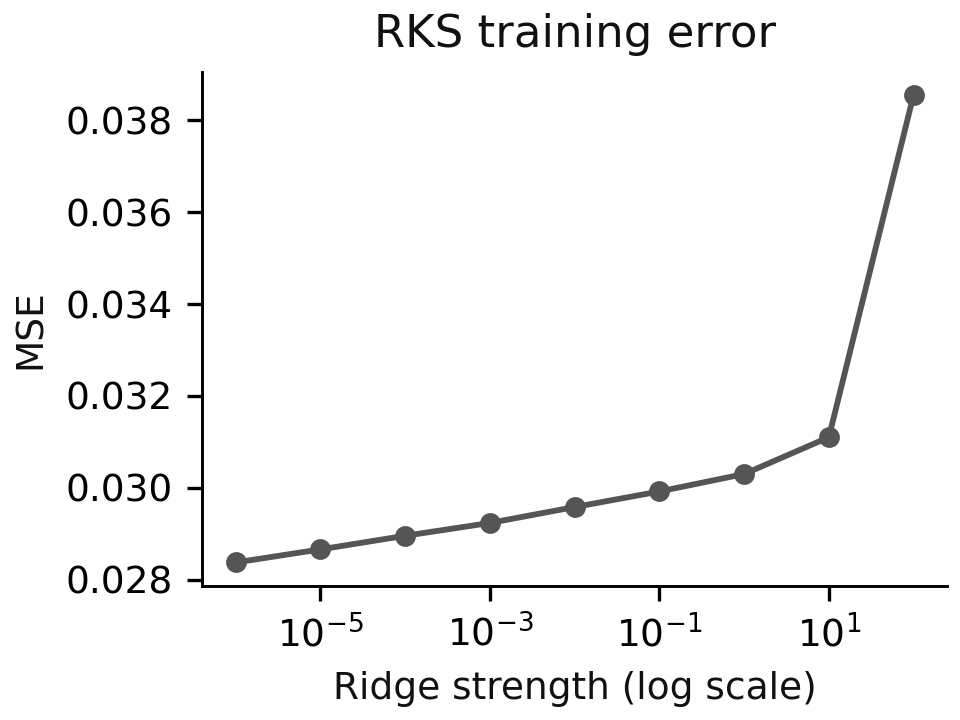

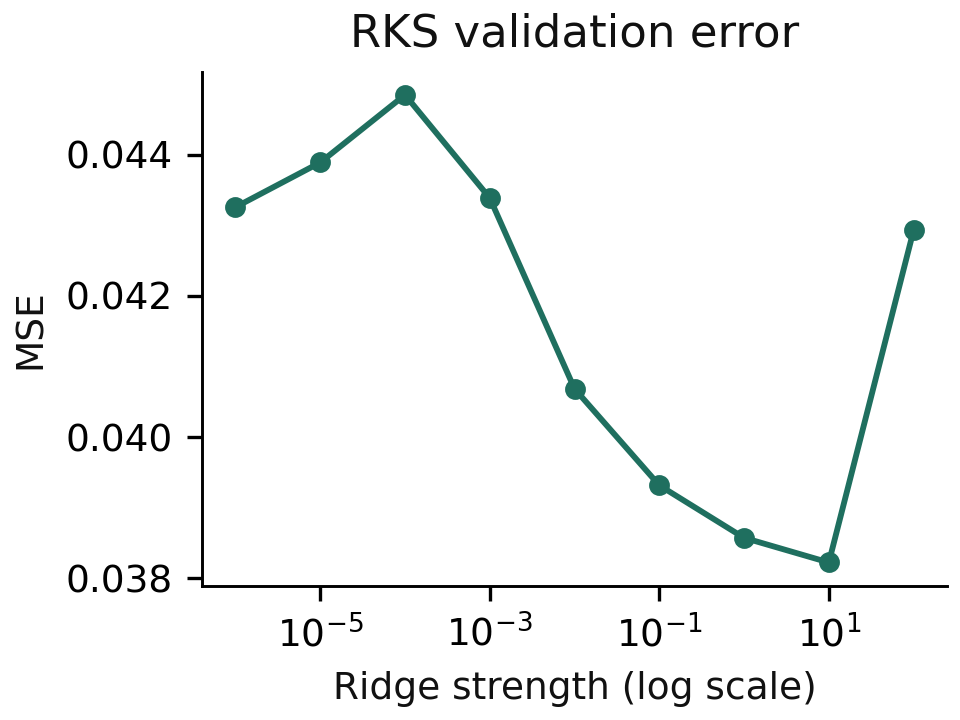

,selected_lambda,validation_mse
0,10.0,0.038224


In [7]:
best_ridge = rks_results.loc[rks_results.val_mse.idxmin(), 'ridge_lambda']
for (metric, title, color) in [('train_mse', 'RKS training error', '#555555'), ('val_mse', 'RKS validation error', '#1F6F5F')]:
    (fig, ax) = plt.subplots(figsize=(3.2, 2.4), layout='constrained')
    ax.semilogx(rks_results.ridge_lambda, rks_results[metric], 'o-', color=color, linewidth=1.4, markersize=4)
    ax.set(xlabel='Ridge strength (log scale)', ylabel='MSE', title=title)
    save_figure(fig, folder, 'rks_' + metric)
pd.DataFrame([{"selected_lambda": best_ridge, "validation_mse": rks_results.val_mse.min()}])


### Part (c)

In [8]:
def fit_mlp(x, y, width):
    torch.manual_seed(42)
    model = nn.Sequential(nn.Linear(2, width), nn.Tanh(), nn.Linear(width, 1))
    optimizer = torch.optim.Adam(model.parameters(), lr=0.005)
    for epoch in range(3000):
        optimizer.zero_grad()
        prediction = model(x).squeeze(1)
        loss = ((prediction - y) ** 2).mean()
        loss.backward()
        optimizer.step()
    model.eval()
    return model

def predict_mlp(model, x):
    with torch.no_grad():
        return model(torch.tensor(x, dtype=torch.float32)).squeeze(1).numpy()


In [9]:
x_tensor = torch.tensor(x_train, dtype=torch.float32)
y_tensor = torch.tensor(y_train, dtype=torch.float32)
mlp_rows = []
for width in [16, 32, 64, 128, 256]:
    model = fit_mlp(x_tensor, y_tensor, width)
    row = {'width': width, 'train_mse': np.mean((predict_mlp(model, x_train) - y_train) ** 2), 'val_mse': np.mean((predict_mlp(model, x_val) - y_val) ** 2)}
    mlp_rows.append(row)
mlp_results = pd.DataFrame(mlp_rows)
mlp_results.to_csv(folder / 'mlp_sweep.csv', index=False)
mlp_results


,width,train_mse,val_mse
0,16,0.033103,0.038125
1,32,0.033032,0.036143
2,64,0.031482,0.039160
3,128,0.030344,0.037761
4,256,0.030302,0.036909


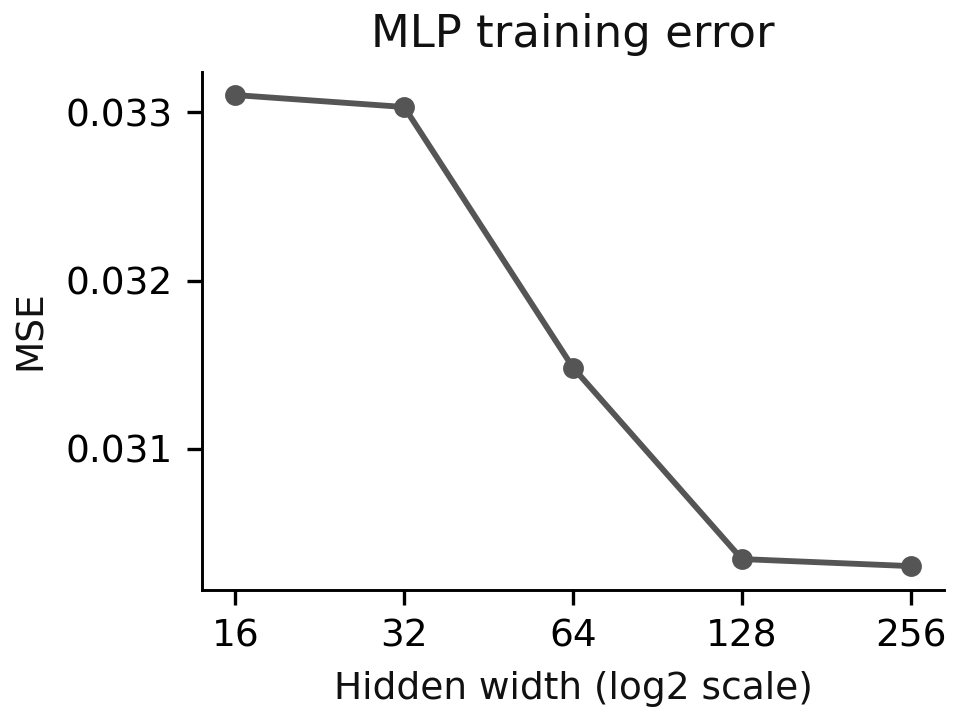

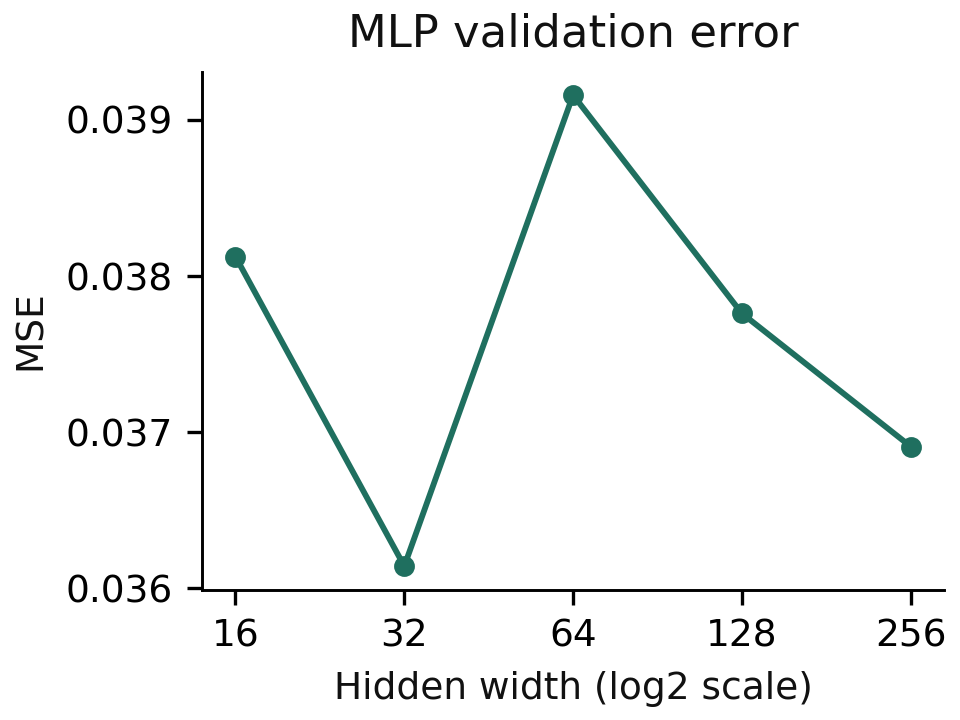

,selected_width,validation_mse
0,32,0.036143


In [10]:
best_width = int(mlp_results.loc[mlp_results.val_mse.idxmin(), 'width'])
for (metric, title, color) in [('train_mse', 'MLP training error', '#555555'), ('val_mse', 'MLP validation error', '#1F6F5F')]:
    (fig, ax) = plt.subplots(figsize=(3.2, 2.4), layout='constrained')
    ax.plot(mlp_results.width, mlp_results[metric], 'o-', color=color, linewidth=1.4, markersize=4)
    ax.set_xscale('log', base=2)
    ax.set(xlabel='Hidden width (log2 scale)', ylabel='MSE', title=title)
    ax.set_xticks([16, 32, 64, 128, 256])
    ax.set_xticklabels([16, 32, 64, 128, 256])
    save_figure(fig, folder, 'mlp_' + metric)
pd.DataFrame([{"selected_width": best_width, "validation_mse": mlp_results.val_mse.min()}])


### Part (d)

In [11]:
coefficients = fit_rks(z_train, y_train, best_ridge)
model = fit_mlp(x_tensor, y_tensor, best_width)
pd.DataFrame({'prediction': features(x_test, w, b) @ coefficients}).to_csv(folder / 'rks_test_predictions.csv', index=False, header=False)
pd.DataFrame({'prediction': predict_mlp(model, x_test)}).to_csv(folder / 'mlp_test_predictions.csv', index=False, header=False)
comparison = pd.DataFrame([{'model': 'RKS', 'selected_parameter': best_ridge, 'train_mse': np.mean((z_train @ coefficients - y_train) ** 2), 'val_mse': np.mean((z_val @ coefficients - y_val) ** 2)}, {'model': 'MLP', 'selected_parameter': best_width, 'train_mse': np.mean((predict_mlp(model, x_train) - y_train) ** 2), 'val_mse': np.mean((predict_mlp(model, x_val) - y_val) ** 2)}])
comparison.to_csv(folder / 'results.csv', index=False)
comparison


/var/folders/9k/yp1kgkk11jn_rp2j3jb0pbr40000gn/T/ipykernel_41085/3196502572.py:9: RuntimeWarning: divide by zero encountered in matmul
  return np.linalg.solve(z.T @ z + ridge * penalty, z.T @ y)
/var/folders/9k/yp1kgkk11jn_rp2j3jb0pbr40000gn/T/ipykernel_41085/3196502572.py:9: RuntimeWarning: overflow encountered in matmul
  return np.linalg.solve(z.T @ z + ridge * penalty, z.T @ y)
/var/folders/9k/yp1kgkk11jn_rp2j3jb0pbr40000gn/T/ipykernel_41085/3196502572.py:9: RuntimeWarning: invalid value encountered in matmul
  return np.linalg.solve(z.T @ z + ridge * penalty, z.T @ y)


/var/folders/9k/yp1kgkk11jn_rp2j3jb0pbr40000gn/T/ipykernel_41085/3196502572.py:2: RuntimeWarning: divide by zero encountered in matmul
  angles = x @ w + b
/var/folders/9k/yp1kgkk11jn_rp2j3jb0pbr40000gn/T/ipykernel_41085/3196502572.py:2: RuntimeWarning: overflow encountered in matmul
  angles = x @ w + b
/var/folders/9k/yp1kgkk11jn_rp2j3jb0pbr40000gn/T/ipykernel_41085/3196502572.py:2: RuntimeWarning: invalid value encountered in matmul
  angles = x @ w + b
/var/folders/9k/yp1kgkk11jn_rp2j3jb0pbr40000gn/T/ipykernel_41085/2822441670.py:3: RuntimeWarning: divide by zero encountered in matmul
  pd.DataFrame({'prediction': features(x_test, w, b) @ coefficients}).to_csv(folder / 'rks_test_predictions.csv', index=False, header=False)
/var/folders/9k/yp1kgkk11jn_rp2j3jb0pbr40000gn/T/ipykernel_41085/2822441670.py:3: RuntimeWarning: overflow encountered in matmul
  pd.DataFrame({'prediction': features(x_test, w, b) @ coefficients}).to_csv(folder / 'rks_test_predictions.csv', index=False, header=

,model,selected_parameter,train_mse,val_mse
0,RKS,10.0,0.031101,0.038224
1,MLP,32.0,0.033032,0.036143


/var/folders/9k/yp1kgkk11jn_rp2j3jb0pbr40000gn/T/ipykernel_41085/3196502572.py:2: RuntimeWarning: divide by zero encountered in matmul
  angles = x @ w + b
/var/folders/9k/yp1kgkk11jn_rp2j3jb0pbr40000gn/T/ipykernel_41085/3196502572.py:2: RuntimeWarning: overflow encountered in matmul
  angles = x @ w + b
/var/folders/9k/yp1kgkk11jn_rp2j3jb0pbr40000gn/T/ipykernel_41085/3196502572.py:2: RuntimeWarning: invalid value encountered in matmul
  angles = x @ w + b
/var/folders/9k/yp1kgkk11jn_rp2j3jb0pbr40000gn/T/ipykernel_41085/2281044002.py:4: RuntimeWarning: divide by zero encountered in matmul
  surfaces = [features(points, w, b) @ coefficients, predict_mlp(model, points)]
/var/folders/9k/yp1kgkk11jn_rp2j3jb0pbr40000gn/T/ipykernel_41085/2281044002.py:4: RuntimeWarning: overflow encountered in matmul
  surfaces = [features(points, w, b) @ coefficients, predict_mlp(model, points)]
/var/folders/9k/yp1kgkk11jn_rp2j3jb0pbr40000gn/T/ipykernel_41085/2281044002.py:4: RuntimeWarning: invalid value e

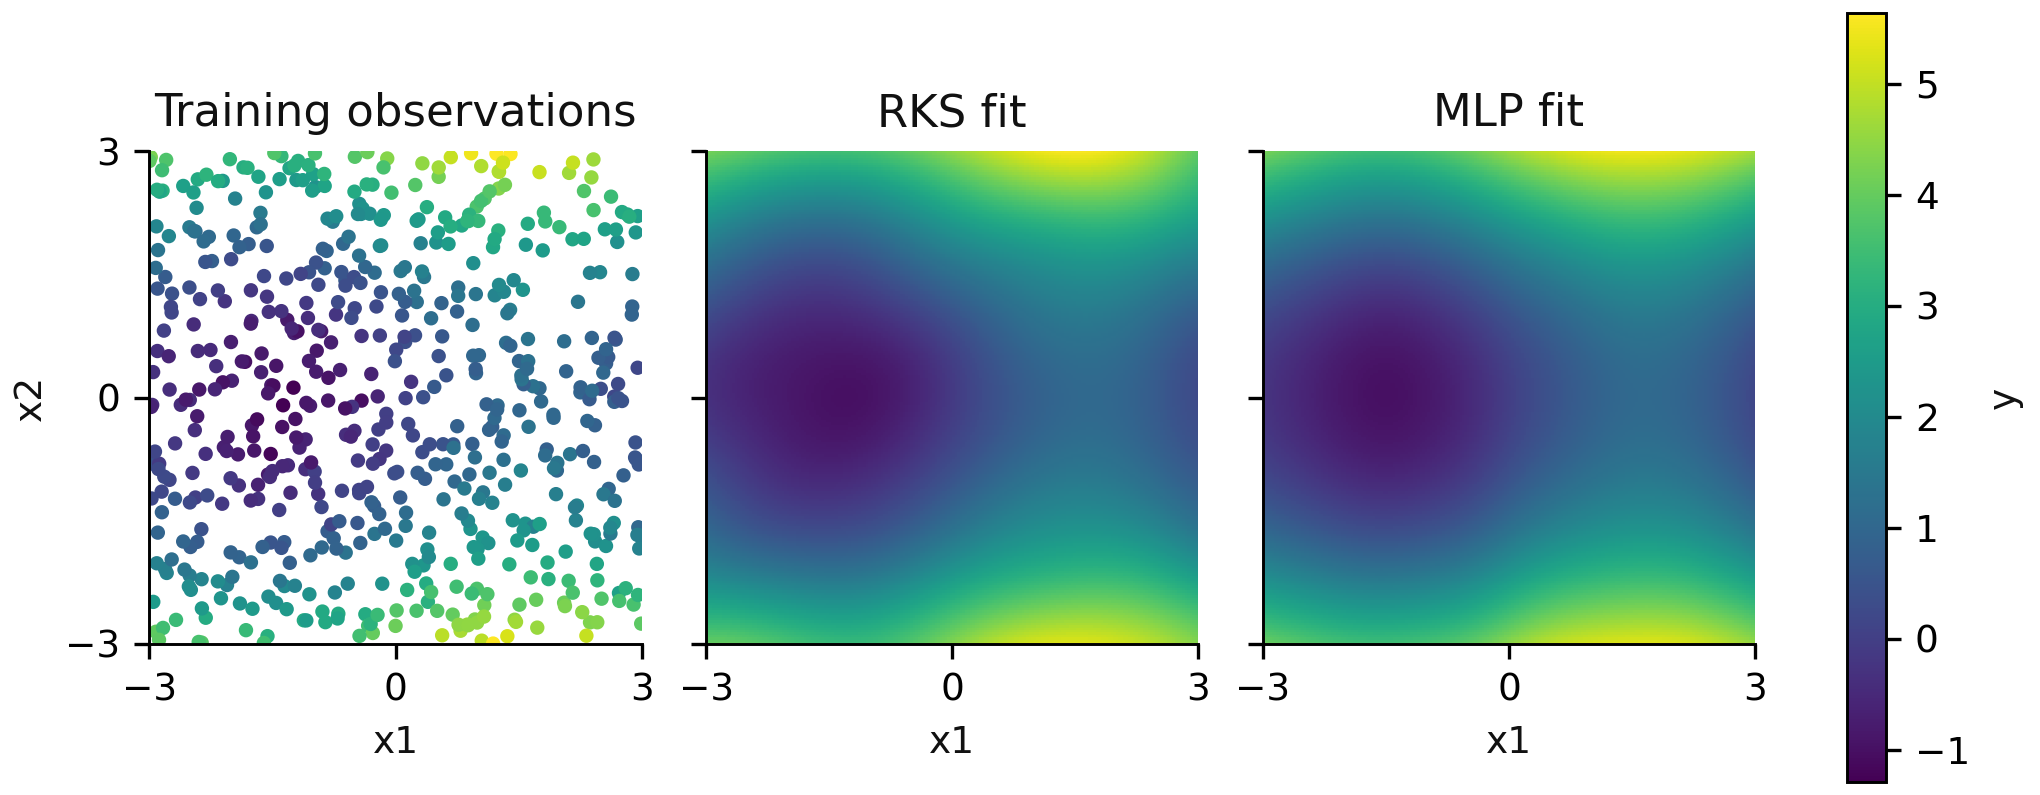

In [12]:
grid = np.linspace(-3, 3, 200)
(x1, x2) = np.meshgrid(grid, grid)
points = np.column_stack([x1.ravel(), x2.ravel()])
surfaces = [features(points, w, b) @ coefficients, predict_mlp(model, points)]
(fig, axes) = plt.subplots(1, 3, figsize=(6.8, 2.65), layout='constrained', sharex=True, sharey=True)
axes[0].scatter(x_train[:, 0], x_train[:, 1], c=y_train, s=6, cmap='viridis', vmin=low, vmax=high)
for (ax, surface) in zip(axes[1:], surfaces):
    image = ax.pcolormesh(x1, x2, surface.reshape(200, 200), cmap='viridis', vmin=low, vmax=high, shading='auto', rasterized=True)
for (ax, title) in zip(axes, ['Training observations', 'RKS fit', 'MLP fit']):
    ax.set(xlabel='x1', title=title, aspect='equal', xlim=(-3, 3), ylim=(-3, 3))
    ax.set_xticks([-3, 0, 3])
    ax.set_yticks([-3, 0, 3])
axes[0].set_ylabel('x2')
fig.colorbar(image, ax=axes, label='y')
save_figure(fig, folder, 'fitted_functions')


In [13]:
pd.DataFrame({"file": ["rks_test_predictions.csv", "mlp_test_predictions.csv"], "predictions": [len(pd.read_csv(folder / "rks_test_predictions.csv", header=None)), len(pd.read_csv(folder / "mlp_test_predictions.csv", header=None))]})


,file,predictions
0,rks_test_predictions.csv,200
1,mlp_test_predictions.csv,200
